# Step 5. Predict cluster anemia prevalence: linear regression vs random forest.

* Features: open defecation, malaria, rainfall anomaly, long-term rainfall,
    wealth, maternal education, urban, and a spatial lag (average anemia of the
    10 nearest *training* clusters, so the test set never leaks into features).
  * 80/20 train/test split, 5-fold cross-validation, grid search for the forest.
  * Out-of-fold predictions for every cluster -> where does the model miss?

Input : data/private/clusters_profiles.parquet
Output: data/private/clusters_final.parquet               (private)
        data/public/model_scores.csv, feature_importance.csv (public)

*Run on the author's computer. The DHS data are private, so the outputs shown here are summaries only (no cluster locations or survey records).*

In [1]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.neighbors import BallTree
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from config import PRIVATE, PUBLIC

In [2]:
BASE_FEATURES = ["od_pct", "pfpr", "rain_3mo_z", "rain_annual_mm", "wealth",
                 "mom_secondary_pct", "urban"]
LABELS = {"od_pct": "Open defecation (%)", "pfpr": "Malaria prevalence (%)",
          "rain_3mo_z": "Rainfall anomaly, last 3 months", "rain_annual_mm": "Typical annual rainfall",
          "wealth": "Household wealth", "mom_secondary_pct": "Mothers with secondary school (%)",
          "urban": "Urban", "spatial_lag": "Anemia in nearby clusters"}
K_NEIGHBORS = 10
y_col = "anemia_pct"

In [3]:
cl = pd.read_parquet(PRIVATE / "clusters_profiles.parquet")
cl = cl.dropna(subset=BASE_FEATURES + [y_col]).reset_index(drop=True)
print(f"{len(cl):,} clusters with complete features")

21,661 clusters with complete features


In [4]:
def spatial_lag(train_idx, target_idx, k=K_NEIGHBORS):
    """Mean anemia of the k nearest training clusters (excluding the cluster itself)."""
    tr = cl.loc[train_idx]
    tree = BallTree(np.radians(tr[["lat", "lon"]].to_numpy()), metric="haversine")
    dist, ind = tree.query(np.radians(cl.loc[target_idx, ["lat", "lon"]].to_numpy()), k=k + 1)
    tr_ids = tr.index.to_numpy()[ind]                       # (n, k+1) training-cluster ids
    vals = tr[y_col].to_numpy()[ind]
    self_hit = tr_ids == np.asarray(target_idx)[:, None]
    vals = np.where(self_hit, np.nan, vals)
    # keep the first k non-self neighbours
    return np.array([row[~np.isnan(row)][:k].mean() for row in vals])

In [5]:
FEATURES = BASE_FEATURES + ["spatial_lag"]

In [6]:
def make_xy(train_idx, test_idx):
    Xtr = cl.loc[train_idx, BASE_FEATURES].copy(); Xtr["spatial_lag"] = spatial_lag(train_idx, train_idx)
    Xte = cl.loc[test_idx, BASE_FEATURES].copy();  Xte["spatial_lag"] = spatial_lag(train_idx, test_idx)
    return Xtr, cl.loc[train_idx, y_col], Xte, cl.loc[test_idx, y_col]

In [7]:
train_idx, test_idx = train_test_split(cl.index, test_size=0.2, random_state=42)
Xtr, ytr, Xte, yte = make_xy(train_idx, test_idx)

In [8]:
cv = KFold(5, shuffle=True, random_state=0)
grid = GridSearchCV(
    RandomForestRegressor(random_state=0, n_jobs=-1),
    {"n_estimators": [300], "max_depth": [10, 20, None], "min_samples_leaf": [5, 20],
     "max_features": [0.33, 0.66]},
    cv=cv, scoring="r2", n_jobs=1)

In [9]:
def cv_r2(make_model, feats):
    """Average R2 across the 5 cross-validation folds of the training set."""
    return np.mean([r2_score(ytr.iloc[v], make_model().fit(Xtr[feats].iloc[t], ytr.iloc[t])
                             .predict(Xtr[feats].iloc[v])) for t, v in cv.split(Xtr)])

In [10]:
grid.fit(Xtr[FEATURES], ytr)                      # grid search with 5-fold CV
best = {k: v for k, v in grid.best_params_.items()}
make_linear = lambda: make_pipeline(StandardScaler(), LinearRegression())
make_rf = lambda: RandomForestRegressor(random_state=0, n_jobs=-1, **best)

In [11]:
rows = []
for name, make_model, feats in [("Linear regression", make_linear, FEATURES),
                                ("Random forest", make_rf, FEATURES),
                                ("Random forest (no spatial lag)", make_rf, BASE_FEATURES)]:
    model = make_model().fit(Xtr[feats], ytr)
    pred = model.predict(Xte[feats])
    rows.append({"model": name, "cv_r2": cv_r2(make_model, feats), "test_r2": r2_score(yte, pred),
                 "test_mae": mean_absolute_error(yte, pred)})
    print(rows[-1])
    if name == "Linear regression":
        linear = model
print("Best forest:", grid.best_params_)
scores = pd.DataFrame(rows)
scores.round(3).to_csv(PUBLIC / "model_scores.csv", index=False)

{'model': 'Linear regression', 'cv_r2': np.float64(0.30907691007476396), 'test_r2': 0.3196155217540788, 'test_mae': 16.00363497173131}


{'model': 'Random forest', 'cv_r2': np.float64(0.3403008735177515), 'test_r2': 0.3476153217688027, 'test_mae': 15.64994623995741}


{'model': 'Random forest (no spatial lag)', 'cv_r2': np.float64(0.28977509600260265), 'test_r2': 0.3086446326017912, 'test_mae': 16.160765546924438}
Best forest: {'max_depth': None, 'max_features': 0.33, 'min_samples_leaf': 5, 'n_estimators': 300}


## Which factors matter? (permutation importance on the test set)

In [12]:
rf = grid.best_estimator_
imp = permutation_importance(rf, Xte[FEATURES], yte, n_repeats=10, random_state=0, n_jobs=-1)
lin_coef = linear.named_steps["linearregression"].coef_
fi = pd.DataFrame({"feature": FEATURES, "label": [LABELS[f] for f in FEATURES],
                   "rf_importance": imp.importances_mean, "rf_importance_sd": imp.importances_std,
                   "linear_std_coef": lin_coef})
fi.sort_values("rf_importance", ascending=False).round(4).to_csv(PUBLIC / "feature_importance.csv", index=False)
print(fi.sort_values("rf_importance", ascending=False).round(3).to_string(index=False))

          feature                             label  rf_importance  rf_importance_sd  linear_std_coef
      spatial_lag         Anemia in nearby clusters          0.233             0.007           10.208
             pfpr            Malaria prevalence (%)          0.109             0.004            3.394
   rain_annual_mm           Typical annual rainfall          0.029             0.003           -0.359
mom_secondary_pct Mothers with secondary school (%)          0.020             0.003           -1.385
           wealth                  Household wealth          0.013             0.002           -2.043
           od_pct               Open defecation (%)          0.012             0.002            0.705
       rain_3mo_z   Rainfall anomaly, last 3 months          0.008             0.002           -0.032
            urban                             Urban          0.002             0.000            0.675


## Out-of-fold predictions for every cluster (for the error map)

In [13]:
cl["pred_rf"] = np.nan
cl["pred_linear"] = np.nan
for t, v in KFold(5, shuffle=True, random_state=1).split(cl):
    Xa, ya, Xb, _ = make_xy(cl.index[t], cl.index[v])
    cl.loc[cl.index[v], "pred_rf"] = make_rf().fit(Xa, ya).predict(Xb)
    cl.loc[cl.index[v], "pred_linear"] = make_linear().fit(Xa, ya).predict(Xb)
cl["resid_rf"] = cl[y_col] - cl.pred_rf             # + = model under-predicts anemia
cl["abs_err_rf"] = cl.resid_rf.abs()
print("Out-of-fold R2 (rf / linear):", round(r2_score(cl[y_col], cl.pred_rf), 3),
      round(r2_score(cl[y_col], cl.pred_linear), 3))

Out-of-fold R2 (rf / linear): 0.34 0.311


In [14]:
cl.to_parquet(PRIVATE / "clusters_final.parquet", index=False)

## Feature importance

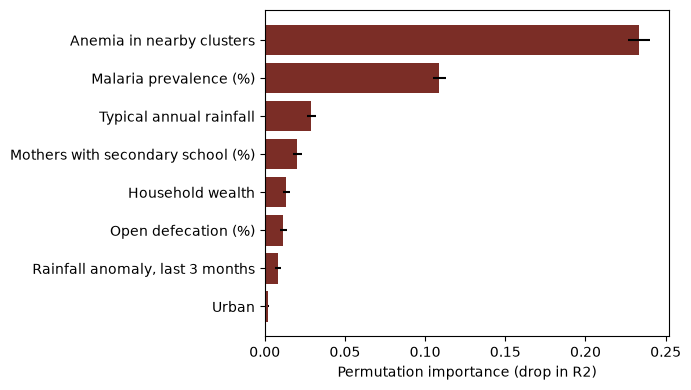

In [15]:
import matplotlib.pyplot as plt
f = fi.sort_values("rf_importance")
plt.figure(figsize=(7, 4))
plt.barh(f.label, f.rf_importance, xerr=f.rf_importance_sd, color="#7b2d26")
plt.xlabel("Permutation importance (drop in R2)"); plt.tight_layout(); plt.show()

## Predicted vs actual (out-of-fold)

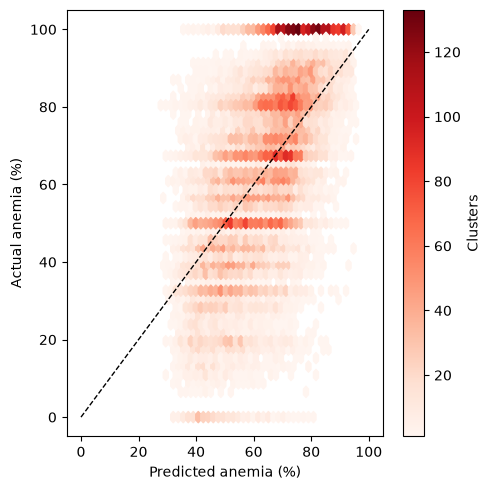

In [16]:
plt.figure(figsize=(5, 5))
plt.hexbin(cl.pred_rf, cl[y_col], gridsize=40, cmap="Reds", mincnt=1)
plt.plot([0, 100], [0, 100], "k--", lw=1)
plt.xlabel("Predicted anemia (%)"); plt.ylabel("Actual anemia (%)")
plt.colorbar(label="Clusters"); plt.tight_layout(); plt.show()